# 07 — Monitoramento e gatilhos de revisão

A taxa manual em produção é acompanhada mês a mês. Três peças:
1. **A/E da carteira contra a taxa manual**, mês a mês e nos últimos 12 meses maduros, com limites de controle de 95% e
   99,8% (quantis exatos de Poisson dado o esperado). Os meses mais recentes, ainda sem todos os avisos, são completados
   pelo padrão de aviso (IBNR) e ficam fora do A/E móvel.
2. **Funnel plot dos grupos** (Spiegelhalter, 2005): A/E de cada estipulante contra o seu esperado, com limites que
   incluem a variância entre grupos (em vida em grupo, cada grupo tem mortalidade própria; sem isso, o funil
   "dispararia" sempre).
3. **Gatilhos objetivos** (`config/monitoramento.yaml`), cada um com a ação correspondente.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Memory
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, monitoramento as Mo

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
cfg, cmo = carregar_config("base", RAIZ), carregar_config("monitoramento", RAIZ)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")
cache = Memory(RAIZ / "data/processed/cache", verbose=0).cache
serie = cache(Mo.serie_mensal)(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua, tabela,
                               cfg["data_referencia"], cmo["meses"])
J, NIV, IM = cmo["janela_meses"], cmo["niveis"], cmo["meses_imaturos"]
cart = Mo.carteira_mensal(serie, NIV, J, IM)
grupos = Mo.funil(serie, NIV, J, IM)

## 1. A/E da carteira contra a taxa manual

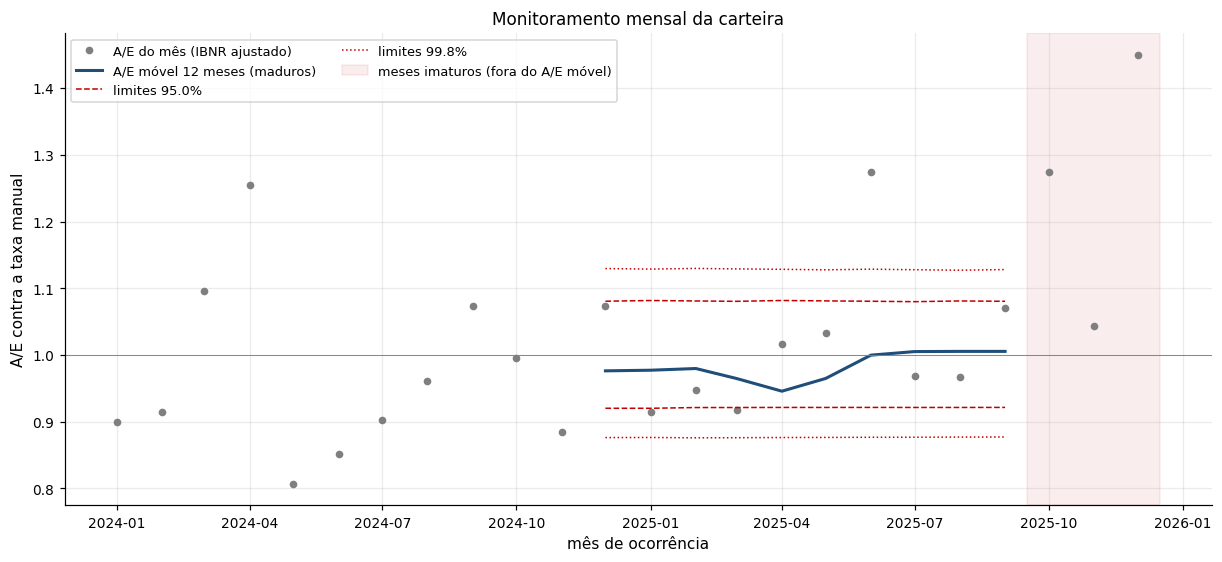

,E_manual,N,N_ajustado,A/E,imaturo,A/E 12m,lim inf 95.0%,lim sup 95.0%,lim inf 99.8%,lim sup 99.8%
mes,,,,,,,,,,
2025-07,52.469,46.000,50.785,0.968,False,1.005,0.921,1.080,0.877,1.128
2025-08,52.638,44.000,50.884,0.967,False,1.005,0.921,1.081,0.877,1.127
2025-09,51.147,44.000,54.750,1.070,False,1.005,0.921,1.080,0.877,1.128
2025-10,53.102,47.000,67.693,1.275,True,NaN,NaN,NaN,NaN,NaN
2025-11,51.656,26.000,53.863,1.043,True,NaN,NaN,NaN,NaN,NaN
2025-12,53.723,12.000,77.892,1.450,True,NaN,NaN,NaN,NaN,NaN


In [2]:
x = cart.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(x, cart["A/E"], "o", color="#7f7f7f", ms=4, label="A/E do mês (IBNR ajustado)")
ax.plot(x, cart[f"A/E {J}m"], "-", color="#1f4e79", lw=2, label=f"A/E móvel {J} meses (maduros)")
for n, estilo_l in zip(NIV, ["--", ":"]):
    ax.plot(x, cart[f"lim inf {n:.1%}"], estilo_l, color="#c00000", lw=1, label=f"limites {n:.1%}")
    ax.plot(x, cart[f"lim sup {n:.1%}"], estilo_l, color="#c00000", lw=1)
im = cart["imaturo"]
ax.axvspan(x[im].min() - pd.Timedelta(days=15), x[im].max() + pd.Timedelta(days=15), color="#c00000", alpha=0.07,
           label=f"meses imaturos (fora do A/E móvel)")
ax.axhline(1, color="grey", lw=0.6)
ax.set_xlabel("mês de ocorrência"); ax.set_ylabel("A/E contra a taxa manual")
ax.set_title("Monitoramento mensal da carteira"); ax.legend(ncol=2)
plt.show()
cart.tail(6)

## 2. Funnel plot dos grupos

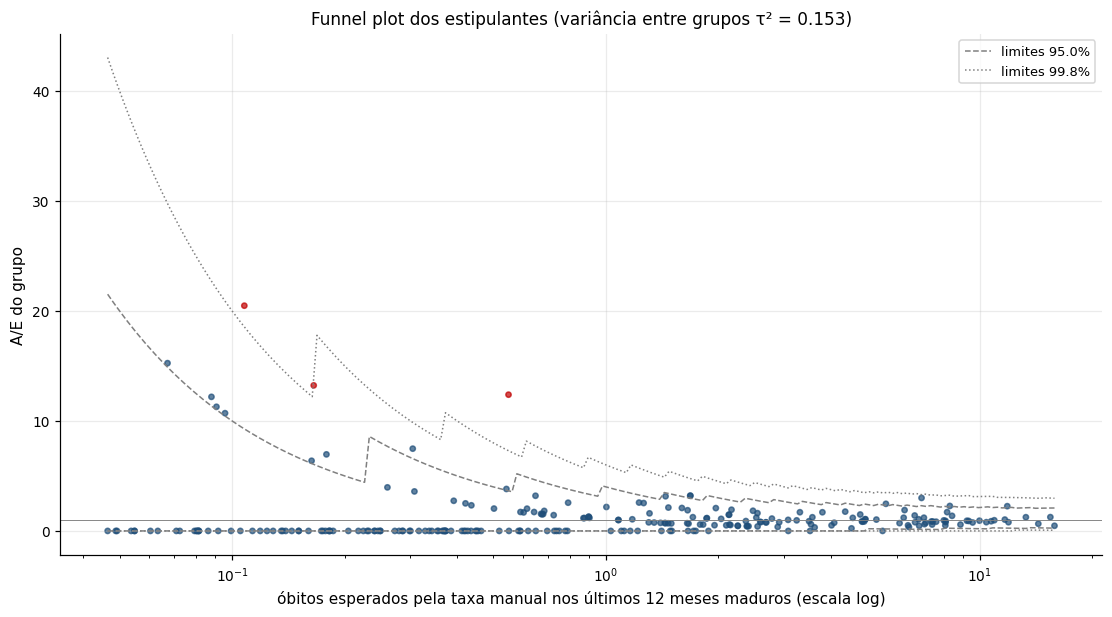

,E_manual,N_ajustado,A/E,lim inf 95.0%,lim sup 95.0%,acima 95.0%,lim inf 99.8%,lim sup 99.8%,acima 99.8%
id_estipulante,,,,,,,,,
EST0074,0.108,2.208,20.473,0.000,9.272,True,0.000,18.544,True
EST0217,0.165,2.187,13.228,0.000,6.048,True,0.000,12.095,True
EST0211,0.549,6.797,12.385,0.000,3.644,True,0.000,7.288,True


In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5))
acima = grupos[f"acima {max(NIV):.1%}"]
ax.scatter(grupos["E_manual"], grupos["A/E"], s=12, color=np.where(acima, "#c00000", "#1f4e79"), alpha=0.7)
e = np.geomspace(grupos["E_manual"].min(), grupos["E_manual"].max(), 200)
for n, ls in zip(NIV, ["--", ":"]):
    inf, sup = Mo.limites_poisson(e, n, grupos.attrs["tau2"])
    ax.plot(e, inf, ls, color="grey", lw=1, label=f"limites {n:.1%}"); ax.plot(e, sup, ls, color="grey", lw=1)
ax.axhline(1, color="grey", lw=0.6); ax.set_xscale("log")
ax.set_xlabel(f"óbitos esperados pela taxa manual nos últimos {J} meses maduros (escala log)")
ax.set_ylabel("A/E do grupo"); ax.set_title(f"Funnel plot dos estipulantes (variância entre grupos τ² = {grupos.attrs['tau2']:.3f})")
ax.legend(); plt.show()
grupos[acima].sort_values("A/E", ascending=False).head(10)

Os grupos acima do limite têm vários óbitos para menos de um esperado: é o perfil de evento com várias mortes
(na carteira sintética, uma hipótese explícita do gerador) ou de problema de cadastro, exatamente o que a investigação
deve separar. Grupos fora do limite superior de 99,8% merecem investigação (cadastro, mudança de atividade, sinistro atípico) e
são exatamente os que a renovação vai reajustar mais. Grupos pequenos ficam dentro do funil mesmo com A/E alto: o
volume não permite distinguir de sorte.

## 3. Gatilhos

In [4]:
gat = Mo.gatilhos(cart, grupos, tabela["meta"], cfg["data_referencia"], cmo)
gat.to_csv(RAIZ / "resultados/07_gatilhos.csv", index=False)
gat

,gatilho,disparou,valor,ação
0,A/E 12m da carteira fora do limite de 99.8%,False,1.005 (limites 0.877 a 1.128),recalibrar a taxa manual (champion/challenger)
1,grupos acima do limite de 99.8%,True,1.20% dos grupos (esperado: 0.10%; limites com...,investigar subscrição e cadastro dos grupos
2,idade da experiência que calibrou a tabela,False,12 meses desde o corte (2024-12-31),ciclo anual de recalibração


## 4. Protocolo de revisão (champion/challenger)

Quando um gatilho dispara, ou no ciclo anual:
1. **Desafiante:** o mesmo pipeline (03b) com a experiência atualizada, e qualquer mudança proposta (fator novo,
   interação, política de anos excluídos) como candidato adicional.
2. **Teste:** fora do tempo, contra o modelo em produção (champion), com a regra de decisão de `config/manual.yaml`
   (IC por bootstrap por estipulante).
3. **Aprovação:** o desafiante só substitui o champion se a regra o escolher; a decisão, os empates e os testes ficam
   registrados nos metadados da nova `artefatos/fatores_manual.yaml`.
4. **Versionamento:** a tabela anterior fica no histórico do git; cotação e renovação passam a ler a nova.